Data loading dan EDA

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("../telco_raw/telco_churn_raw.csv")
df.head()
df.info()
df.describe(include="all")
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


0

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")  # ada spasi kosong
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

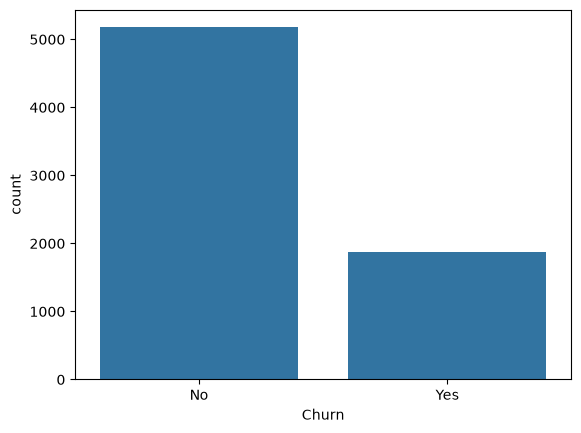

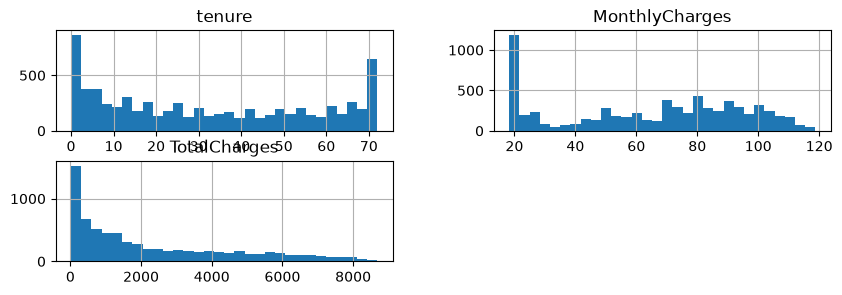

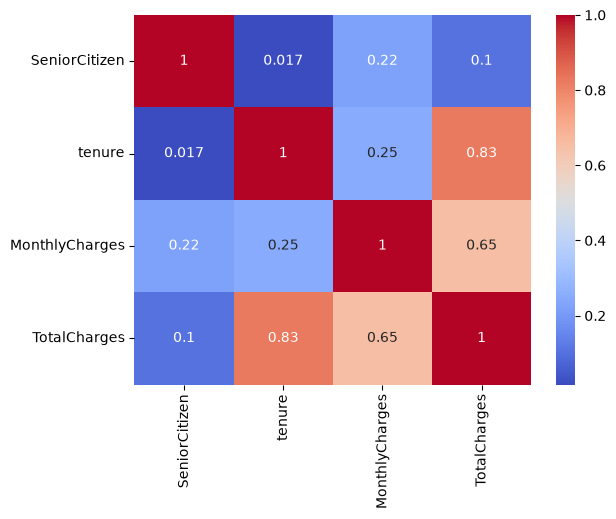

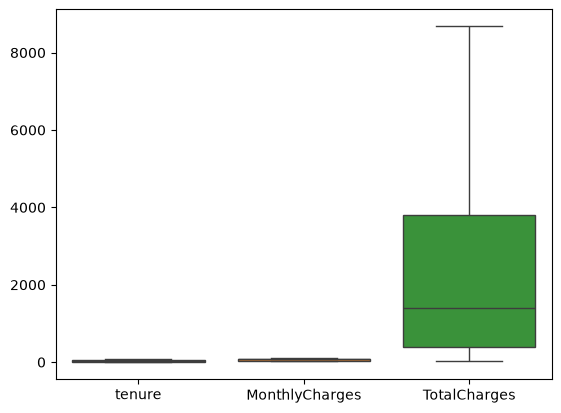

In [4]:
sns.countplot(x="Churn", data=df); plt.show()
df[["tenure","MonthlyCharges","TotalCharges"]].hist(bins=30, figsize=(10,3)); plt.show()
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm"); plt.show()
sns.boxplot(data=df[["tenure","MonthlyCharges","TotalCharges"]]); plt.show()

Preprocessing

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

df = df.drop(columns=["customerID"])
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop_duplicates()

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
for c in num_cols:                                   # outlier: IQR clipping
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    df[c] = df[c].clip(q1 - 1.5*iqr, q3 + 1.5*iqr)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
cat_cols = df.select_dtypes(include="object").columns.tolist()
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["Churn"])
train, test = train.copy(), test.copy()
scaler = StandardScaler()
train[num_cols] = scaler.fit_transform(train[num_cols])
test[num_cols] = scaler.transform(test[num_cols])

import os
os.makedirs("telco_preprocessing", exist_ok=True)
train.to_csv("telco_preprocessing/train.csv", index=False)
test.to_csv("telco_preprocessing/test.csv", index=False)